In [2]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score
)

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

import joblib

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.20.0


In [3]:
df = pd.read_csv("/content/drive/MyDrive/Crop-Recommendation/data/dataset/Crop_recommendation.csv")

print(df.head())
print("\nShape:", df.shape)
print("\nColumns:")
print(df.columns)

    N   P   K  temperature   humidity        ph    rainfall label
0  90  42  43    20.879744  82.002744  6.502985  202.935536  rice
1  85  58  41    21.770462  80.319644  7.038096  226.655537  rice
2  60  55  44    23.004459  82.320763  7.840207  263.964248  rice
3  74  35  40    26.491096  80.158363  6.980401  242.864034  rice
4  78  42  42    20.130175  81.604873  7.628473  262.717340  rice

Shape: (2200, 8)

Columns:
Index(['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall', 'label'], dtype='object')


In [4]:
 df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2200 entries, 0 to 2199
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   N            2200 non-null   int64  
 1   P            2200 non-null   int64  
 2   K            2200 non-null   int64  
 3   temperature  2200 non-null   float64
 4   humidity     2200 non-null   float64
 5   ph           2200 non-null   float64
 6   rainfall     2200 non-null   float64
 7   label        2200 non-null   object 
dtypes: float64(4), int64(3), object(1)
memory usage: 137.6+ KB


In [5]:
print(df.describe())

                 N            P            K  temperature     humidity  \
count  2200.000000  2200.000000  2200.000000  2200.000000  2200.000000   
mean     50.551818    53.362727    48.149091    25.616244    71.481779   
std      36.917334    32.985883    50.647931     5.063749    22.263812   
min       0.000000     5.000000     5.000000     8.825675    14.258040   
25%      21.000000    28.000000    20.000000    22.769375    60.261953   
50%      37.000000    51.000000    32.000000    25.598693    80.473146   
75%      84.250000    68.000000    49.000000    28.561654    89.948771   
max     140.000000   145.000000   205.000000    43.675493    99.981876   

                ph     rainfall  
count  2200.000000  2200.000000  
mean      6.469480   103.463655  
std       0.773938    54.958389  
min       3.504752    20.211267  
25%       5.971693    64.551686  
50%       6.425045    94.867624  
75%       6.923643   124.267508  
max       9.935091   298.560117  


In [6]:
print(df.isnull().sum())

N              0
P              0
K              0
temperature    0
humidity       0
ph             0
rainfall       0
label          0
dtype: int64


In [7]:
print("Duplicates:", df.duplicated().sum())

Duplicates: 0


In [8]:
print(df["label"].value_counts())

label
rice           100
maize          100
chickpea       100
kidneybeans    100
pigeonpeas     100
mothbeans      100
mungbean       100
blackgram      100
lentil         100
pomegranate    100
banana         100
mango          100
grapes         100
watermelon     100
muskmelon      100
apple          100
orange         100
papaya         100
coconut        100
cotton         100
jute           100
coffee         100
Name: count, dtype: int64


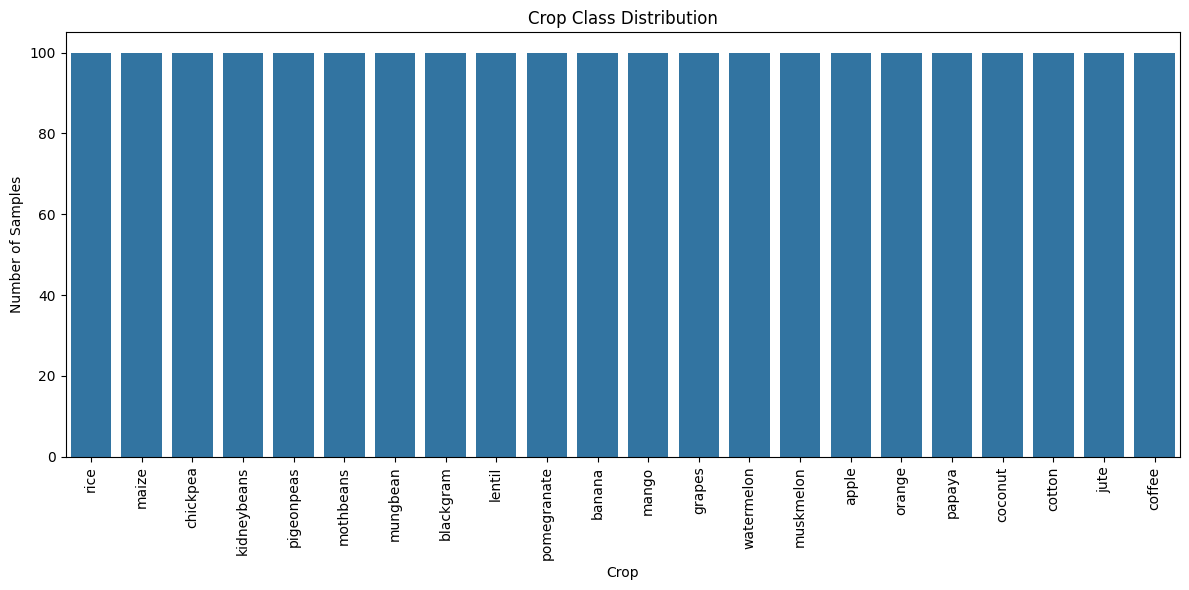

In [9]:
plt.figure(figsize=(12, 6))

sns.countplot(
    data=df,
    x="label",
    order=df["label"].value_counts().index
)

plt.xticks(rotation=90)
plt.title("Crop Class Distribution")
plt.xlabel("Crop")
plt.ylabel("Number of Samples")
plt.tight_layout()
plt.show()

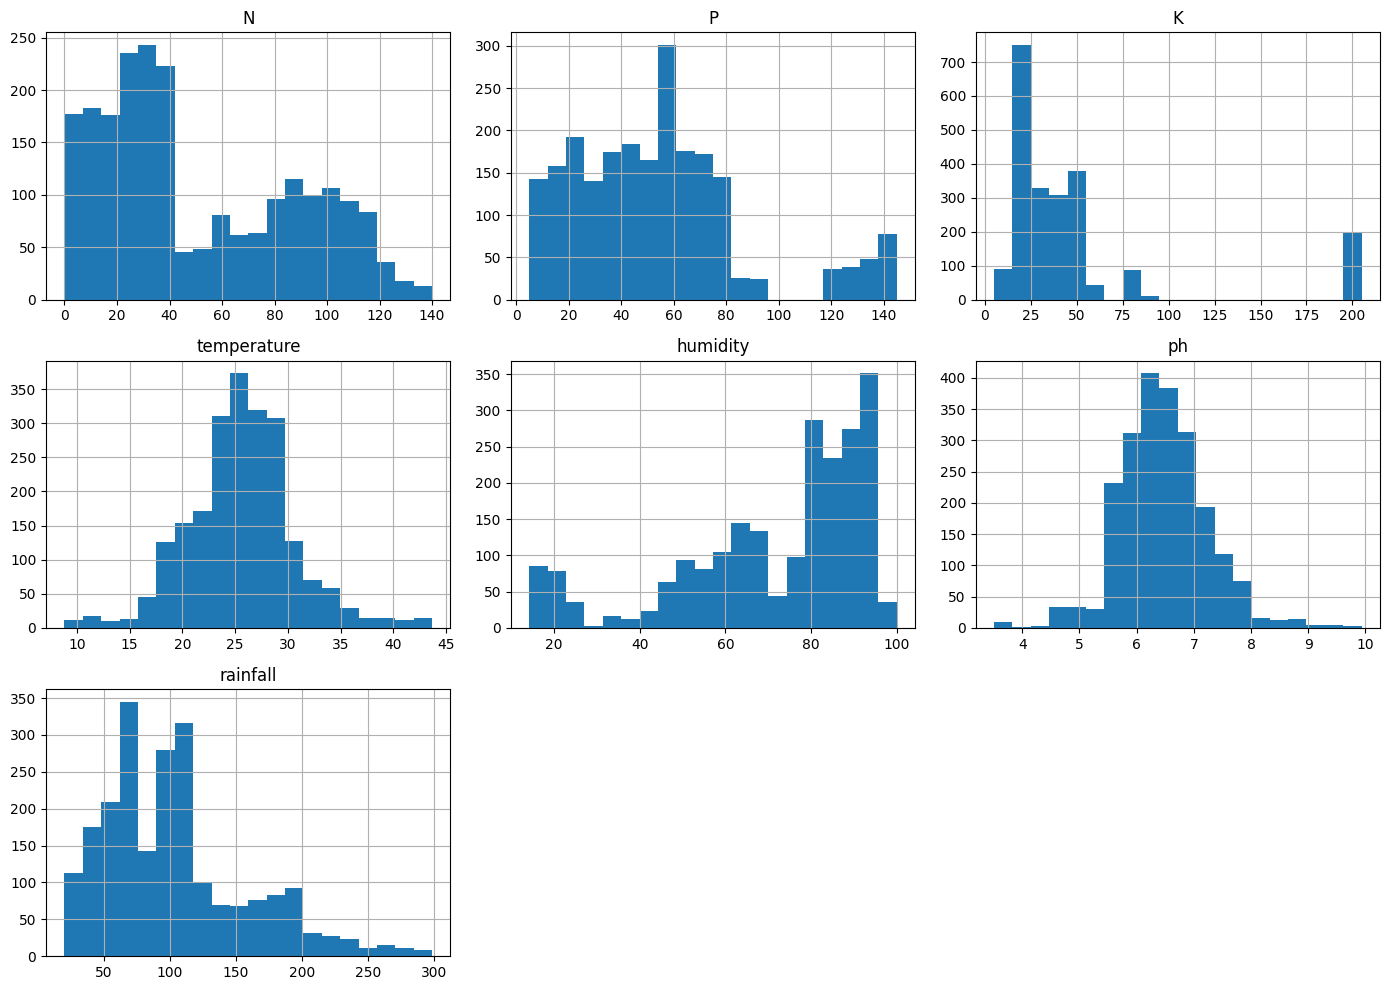

In [10]:
df.hist(
    figsize=(14, 10),
    bins=20
)

plt.tight_layout()
plt.show()

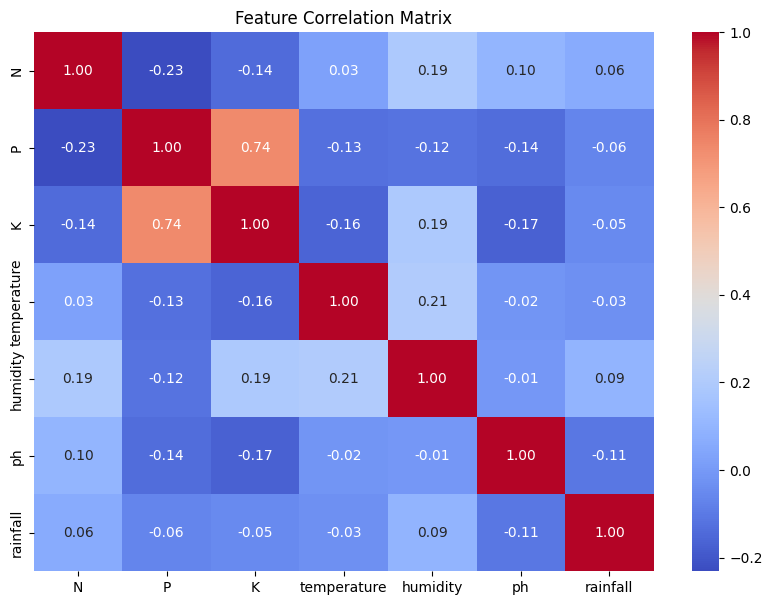

In [11]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    df.drop(columns=["label"]).corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Feature Correlation Matrix")
plt.show()

In [12]:
X = df.drop("label", axis=1)
y = df["label"]

In [13]:
label_encoder = LabelEncoder()

y_encoded = label_encoder.fit_transform(y)

print(label_encoder.classes_)

['apple' 'banana' 'blackgram' 'chickpea' 'coconut' 'coffee' 'cotton'
 'grapes' 'jute' 'kidneybeans' 'lentil' 'maize' 'mango' 'mothbeans'
 'mungbean' 'muskmelon' 'orange' 'papaya' 'pigeonpeas' 'pomegranate'
 'rice' 'watermelon']


In [14]:
num_classes = len(label_encoder.classes_)

print("Number of classes:", num_classes)

Number of classes: 22


In [15]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.20,
    random_state=42,
    stratify=y_encoded
)

In [16]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [17]:
model = keras.Sequential([
    keras.Input(shape=(7,)),

    layers.Dense(64, activation="relu"),
    layers.Dropout(0.20),

    layers.Dense(32, activation="relu"),
    layers.Dropout(0.20),

    layers.Dense(16, activation="relu"),

    layers.Dense(num_classes, activation="softmax")
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 22)             │           374 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,494 (13.65 KB)

 Trainable params: 3,494 (13.65 KB)

 Non-trainable params: 0 (0.00 B)

In [18]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [19]:
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

In [20]:
history = model.fit(
    X_train_scaled,
    y_train,
    validation_split=0.20,
    epochs=100,
    batch_size=32,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/100
44/44 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.0952 - loss: 2.9979 - val_accuracy: 0.1676 - val_loss: 2.8246
Epoch 2/100
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.2074 - loss: 2.6809 - val_accuracy: 0.3153 - val_loss: 2.3368
Epoch 3/100
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.3473 - loss: 2.1607 - val_accuracy: 0.4261 - val_loss: 1.7157
Epoch 4/100
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.4673 - loss: 1.6549 - val_accuracy: 0.6364 - val_loss: 1.2563
Epoch 5/100
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5632 - loss: 1.3163 - val_accuracy: 0.7443 - val_loss: 0.9353
Epoch 6/100
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6392 - loss: 1.0537 - val_accuracy: 0.7898 - val_loss: 0.7241
Epoch 7/100
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6705 - loss: 0.9181 - val_accuracy: 0.8551 - val_loss: 0.5891
Epoch 8/100
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7060 - loss: 0.8271 - val_accuracy: 0.8409 - v

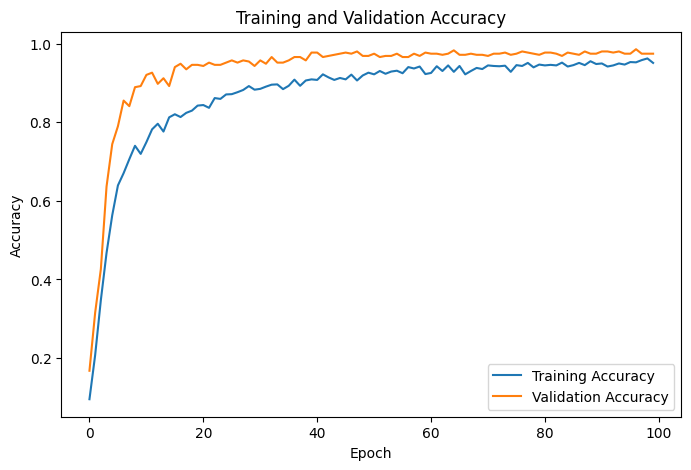

In [21]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.title("Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.show()

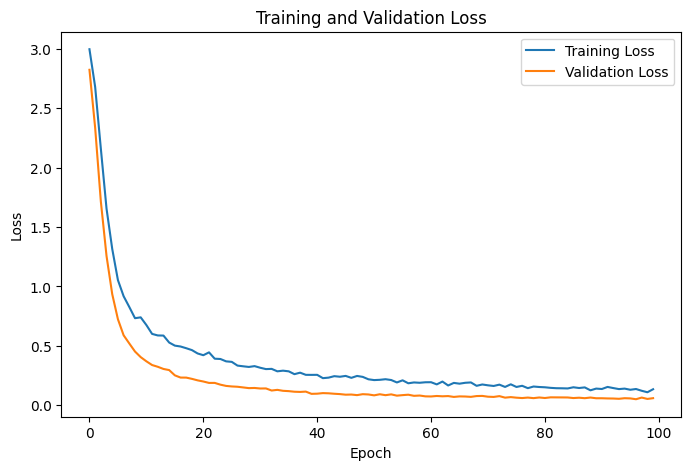

In [22]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.show()

In [23]:
test_loss, test_accuracy = model.evaluate(
    X_test_scaled,
    y_test,
    verbose=0
)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

Test Loss: 0.05634400248527527
Test Accuracy: 0.9750000238418579


In [24]:
y_probability = model.predict(X_test_scaled)

y_pred = np.argmax(y_probability, axis=1)

14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step


In [25]:
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)

Accuracy: 0.975


In [26]:
print(
    classification_report(
        y_test,
        y_pred,
        target_names=label_encoder.classes_
    )
)

              precision    recall  f1-score   support

       apple       1.00      1.00      1.00        20
      banana       1.00      1.00      1.00        20
   blackgram       0.83      1.00      0.91        20
    chickpea       1.00      1.00      1.00        20
     coconut       1.00      1.00      1.00        20
      coffee       1.00      1.00      1.00        20
      cotton       1.00      1.00      1.00        20
      grapes       1.00      1.00      1.00        20
        jute       0.83      0.95      0.88        20
 kidneybeans       1.00      1.00      1.00        20
      lentil       1.00      0.75      0.86        20
       maize       1.00      1.00      1.00        20
       mango       1.00      1.00      1.00        20
   mothbeans       0.91      1.00      0.95        20
    mungbean       1.00      1.00      1.00        20
   muskmelon       1.00      1.00      1.00        20
      orange       1.00      1.00      1.00        20
      papaya       1.00    

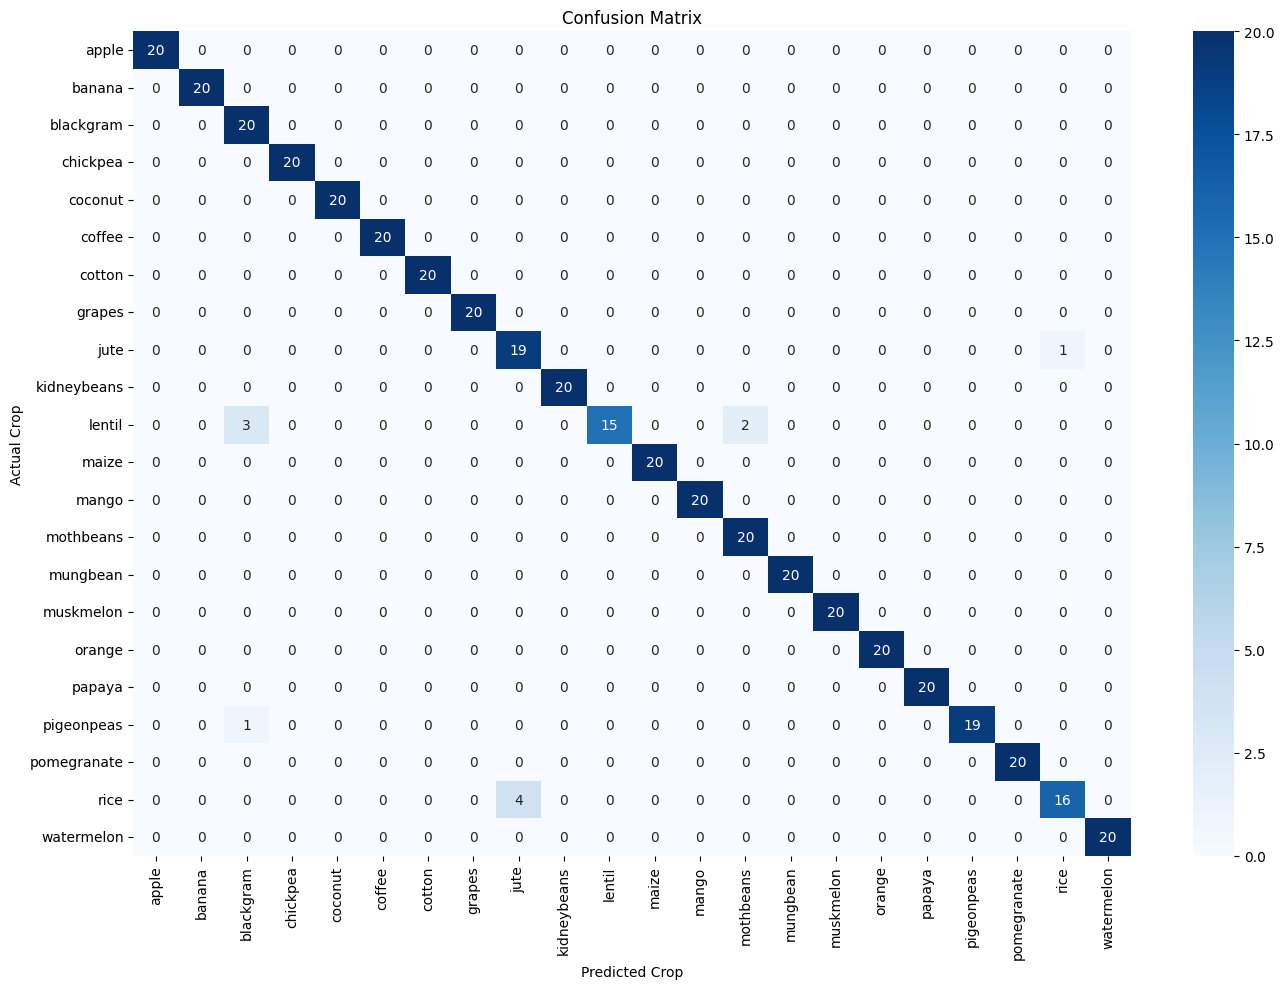

In [27]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(14, 10))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted Crop")
plt.ylabel("Actual Crop")

plt.xticks(rotation=90)
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

In [28]:
def recommend_crop(N, P, K, temperature, humidity, ph, rainfall):

    input_data = np.array([[
        N,
        P,
        K,
        temperature,
        humidity,
        ph,
        rainfall
    ]])

    input_scaled = scaler.transform(input_data)

    probabilities = model.predict(input_scaled, verbose=0)

    predicted_index = np.argmax(probabilities)

    predicted_crop = label_encoder.inverse_transform(
        [predicted_index]
    )[0]

    confidence = probabilities[0][predicted_index] * 100

    return predicted_crop, confidence

In [29]:
crop, confidence = recommend_crop(
    N=90,
    P=42,
    K=43,
    temperature=25.5,
    humidity=80,
    ph=6.5,
    rainfall=200
)

print("Recommended Crop:", crop)
print("Confidence:", round(confidence, 2), "%")

Recommended Crop: jute
Confidence: 55.21 %


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


In [30]:
def top_3_recommendations(
    N, P, K, temperature, humidity, ph, rainfall
):

    input_data = np.array([[
        N, P, K,
        temperature,
        humidity,
        ph,
        rainfall
    ]])

    input_scaled = scaler.transform(input_data)

    probabilities = model.predict(
        input_scaled,
        verbose=0
    )[0]

    top_indices = np.argsort(probabilities)[-3:][::-1]

    results = []

    for index in top_indices:
        crop = label_encoder.inverse_transform([index])[0]
        probability = probabilities[index] * 100

        results.append(
            (crop, probability)
        )

    return results

In [31]:
results = top_3_recommendations(
    90, 42, 43,
    25.5, 80, 6.5, 200
)

for crop, probability in results:
    print(f"{crop}: {probability:.2f}%")

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


jute: 55.21%
rice: 44.74%
papaya: 0.05%


In [32]:
import os
import pandas as pd

results_path = "/content/drive/MyDrive/Crop-Recommendation/results"
os.makedirs(results_path, exist_ok=True)

# Assuming 'results' is available from the previous cell's execution
# results = top_3_recommendations(90, 42, 43, 25.5, 80, 6.5, 200)

# Convert results to a pandas DataFrame for saving
results_df = pd.DataFrame(results, columns=['Crop', 'Confidence (%)'])

output_file_path = os.path.join(results_path, "crop_recommendations.csv")
results_df.to_csv(output_file_path, index=False)

print(f"Results successfully saved to: {output_file_path}")

Results successfully saved to: /content/drive/MyDrive/Crop-Recommendation/results/crop_recommendations.csv


/tmp/ipykernel_668/1005552042.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Crop', y='Confidence (%)', data=results_df, palette='viridis')


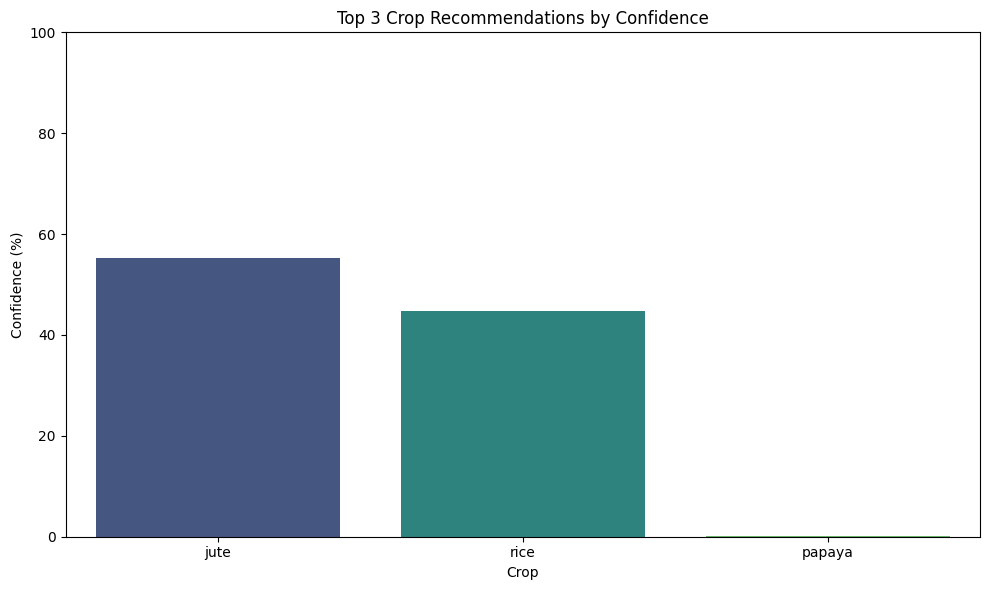

In [33]:
plt.figure(figsize=(10, 6))
sns.barplot(x='Crop', y='Confidence (%)', data=results_df, palette='viridis')
plt.title('Top 3 Crop Recommendations by Confidence')
plt.xlabel('Crop')
plt.ylabel('Confidence (%)')
plt.ylim(0, 100) # Ensure y-axis goes from 0 to 100
plt.tight_layout()
plt.show()

### Storing Model Metrics

I'll now save the model's performance metrics, including the test loss, test accuracy, and a detailed classification report, into a text file within the `results` directory. This will allow for easy access and review of the model's evaluation results.

In [34]:
metrics_file_path = os.path.join(results_path, "model_metrics.txt")

with open(metrics_file_path, "w") as f:
    f.write(f"Test Loss: {test_loss:.4f}\n")
    f.write(f"Test Accuracy: {test_accuracy:.4f}\n\n")
    f.write("Classification Report:\n")
    # Capture the classification report output
    report_str = classification_report(y_test, y_pred, target_names=label_encoder.classes_)
    f.write(report_str)

print(f"Model metrics successfully saved to: {metrics_file_path}")

Model metrics successfully saved to: /content/drive/MyDrive/Crop-Recommendation/results/model_metrics.txt
